# Лекция 8. Актор и критик

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/08-actor-critic/lecture/lecture.ipynb)

**Главный вопрос сегодня: чем сеть-оценка из лекций 6–7 поможет стратегии-сети из лекции 5?**

На лекции 5 стратегия-сеть училась методом REINFORCE и держала шест. На лекциях 6–7 мы учили сеть-оценку, и DQN посадил лунный модуль. Сегодня обе сети работают вместе: стратегия-сеть выбирает действия — её называют **актором**, сеть-оценка говорит, насколько хорошо получилось, — её называют **критиком**.

**Зачем, если DQN уже сажает модуль?** DQN выбирает действие перебором: считает $Q(s, a)$ для каждого действия и берёт наибольшее. У модуля действий четыре, перебрать легко. Но у настоящего аппарата тяга двигателя и угол поворота — числа, а не четыре кнопки: перебрать все значения нельзя. Стратегия-сеть ничего не перебирает, поэтому действие может быть и числом — подробнее в разделе 4. Есть и вторая причина: по таблице $Q$ в каждой ситуации выбирается одно действие, а бывают задачи, где лучшая стратегия — случайная (коридор из лекции 5). На стратегии-сетях построены PPO и обучение роботов, поэтому разберёмся, как их учить быстрее. Проверять будем на том же лунном модуле, чтобы в конце честно сравнить с DQN.

Разделы:

1. Где мы остановились: REINFORCE и лунный модуль
2. Критик: вычитаем то, что от действия не зависит
3. Не ждём конца эпизода: хвост оценивает критик
4. Актор-критик и DQN на одном модуле
5. Итоги

In [1]:
# Ноутбук считается меньше минуты: по умолчанию берутся сохранённые результаты обучения.
TRAIN_LANDER = False      # True — обучить модуль заново: около 3 минут на запуск, в лекции 30 запусков; нужен пакет gymnasium[box2d]
SEEDS = range(10)          # номера запусков
STEPS = 1_000_000         # шагов в среде на один запуск

# Служебные модули: в репозитории лежат рядом, в Google Colab скачиваются заново при каждом запуске.
import pathlib, sys, urllib.request
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main"
FILES = ("08-actor-critic/lecture/ac_core.py", "08-actor-critic/lecture/ac_plots.py",
         "08-actor-critic/lecture/lander_ac_results.npz")
for file in FILES:
    local = pathlib.Path("../..") / file
    if local.exists():
        sys.path.append(str(local.parent))
    else:
        urllib.request.urlretrieve(f"{RAW}/{file}", pathlib.Path(file).name)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from ac_core import *             # лунный модуль и функции лекции 5 для него: make_lander, make_net, play, returns_to_go, log_probs_of
from ac_plots import *            # схемы и картинки этой лекции
torch.set_num_threads(1)          # маленькой сети один поток быстрее

## 1. Где мы остановились: REINFORCE и лунный модуль

**Главная идея: REINFORCE сравнивает результат с одним числом $b$ на все ситуации — шест так удержать можно, а лунный модуль садится редко.**

Среда — лунный модуль из лекции 7: 8 чисел состояния, четыре действия (ничего не делать, левый двигатель, главный, правый). За посадку +100, за аварию −100. Сумма наград 200 и выше значит, что модуль сел; эпизод — не больше 1000 шагов.

**Напомним, что такое $G_t$.** Стратегия-сеть играет эпизод и получает на каждом шаге награду $r_t$. Тогда

$$G_t = r_t + \gamma\, r_{t+1} + \gamma^2 r_{t+2} + \dots$$

— сумма наград с шага $t$ до конца эпизода, дальние награды берутся с дисконтом $\gamma = 0.99$. Это «сколько всего вышло после шага $t$». Вот настоящий эпизод, в котором модуль сел:

эпизод: 286 шагов, сумма наград за эпизод 252
шаг 100: награда -2.0, а G_100 = 53 — с учётом всего, что было после


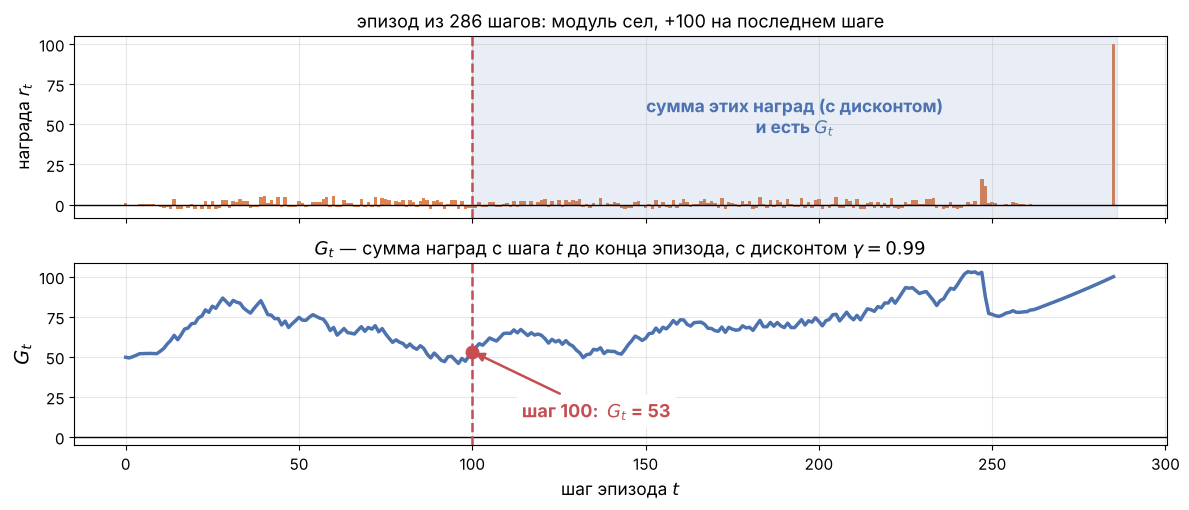

In [3]:
rewards = load_episode()               # награды по шагам одного настоящего эпизода
G = returns_to_go(rewards)             # G_t для каждого шага
print(f"эпизод: {len(rewards)} шагов, сумма наград за эпизод {rewards.sum():.0f}")
print(f"шаг 100: награда {rewards[100]:.1f}, а G_100 = {G[100]:.0f} — с учётом всего, что было после")
plot_returns(rewards, mark=100)
plt.show()

Дальше всё как на лекции 5: сыграли эпизод, посчитали $G_t$ для каждого шага и сделали шаг градиента по

$$\text{loss} = -\sum_t \,(G_t - b)\,\log \pi_\theta(a_t \mid s_t).$$

Число $G_t - b$ — **вес действия**; $b$ — средний $G_t$ всех прошлых шагов.

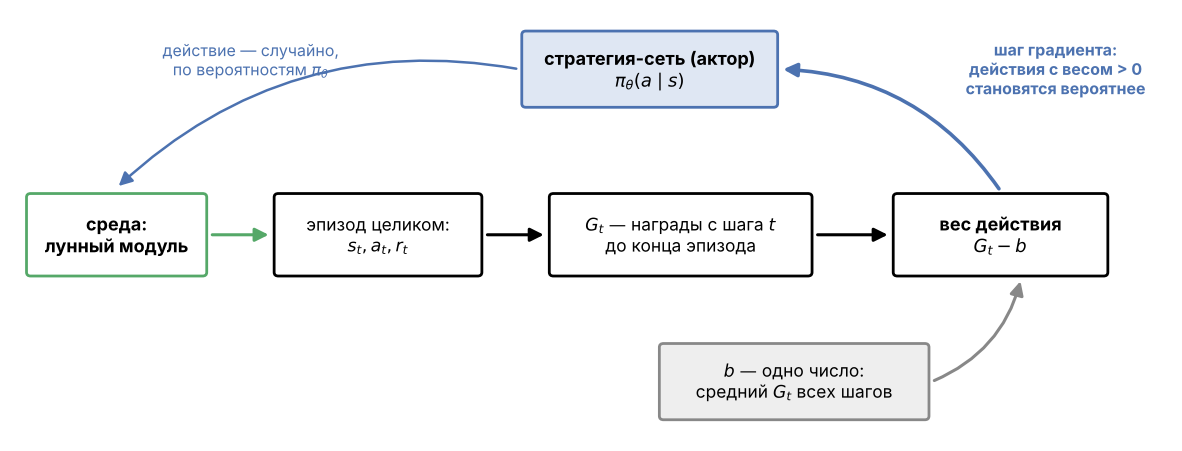

In [3]:
draw_ac_scheme("reinforce")
plt.show()

**Как эта формула двигает стратегию.** $\log \pi_\theta(a_t \mid s_t)$ — это число, которое говорит, насколько вероятным сеть считала то действие, которое агент сыграл: чем вероятнее, тем логарифм ближе к нулю. Шаг градиента меняет веса $\theta$ так, чтобы loss стал меньше. У слагаемого с **положительным** весом для этого нужно поднять $\log \pi_\theta(a_t \mid s_t)$ — то есть сделать сыгранное действие вероятнее; у слагаемого с **отрицательным** весом — наоборот, опустить. Сам вес от $\theta$ не зависит, это просто множитель перед логарифмом: он задаёт, в какую сторону и насколько сильно двигать вероятность сыгранного действия.

**Что будет, если $b = 0$.** Тогда вес равен $G_t$ — «сколько награды собрано после этого шага», без сравнения с чем-либо. На лекции 5 так и начинали: в CartPole каждый шаг даёт +1, поэтому $G_t > 0$ всегда — и вероятнее становилось **каждое** сыгранное действие, в том числе последнее перед падением шеста. Реже оно становилось только потому, что вероятности в сумме дают единицу. Шест тогда стоял 180 шагов вместо 458 с вычитанием $b$.

Значит, $b$ нужен, чтобы вес отвечал на вопрос «вышло лучше или хуже обычного». Весь раздел 2 — о том, с чем сравнивать.

Функции лекции 5 — `make_net`, `play`, `returns_to_go`, `log_probs_of` — переписаны с двух действий на четыре и лежат в `ac_core.py`; сеть стратегии теперь 8 → 64 → 64 → 4.

Цикл обучения — как на лекции 5, только без множителя $\gamma^t$ в весе: посадка идёт сотни шагов, а $0.99^{300} \approx 0.05$. В `history` для каждого эпизода — пара: сколько шагов в среде сделано и сумма наград эпизода.

In [4]:
def train_reinforce(seed, steps=STEPS):
    # REINFORCE лекции 5: вес действия G_t − b, где b — средний G_t всех прошлых шагов
    rng, env, actor = np.random.default_rng(seed), make_lander(), make_net(4, seed)
    opt = torch.optim.Adam(actor.parameters(), lr=0.001)
    b, count, played, history = 0.0, 0, 0, []                             # played — сколько шагов в среде сыграно
    while played < steps:
        s, _ = env.reset(seed=seed * 10_000 + len(history))
        states, actions, rewards, *_ = play(actor, env, s, rng, n=1000)   # эпизод целиком: не больше 1000 шагов
        G = returns_to_go(rewards)                                         # массив: G_t для каждого шага
        weights = torch.as_tensor(G - b, dtype=torch.float32)              # веса действий — числа
        loss = -(weights * log_probs_of(actor, states, actions)).sum()
        opt.zero_grad(); loss.backward(); opt.step()
        for g in G:                                                        # b — средний G_t всех прошлых шагов
            count += 1; b += (g - b) / count
        played += len(rewards); history.append((played, rewards.sum()))
    return np.array(history), actor

REINFORCE: вес G − b
    среднее последних 100 эпизодов: 137; по запускам: 98 120 121 126 130 141 141 142 144 210; не меньше 200 — в 1 из 10
    к 500 тыс. шагов: 121;  до среднего 200 дошли 1 из 10 запусков, шагов до этого, тыс.: 419
    время вышло (1000 шагов) в последних 100 эпизодах, % по запускам: 0 31 58 59 61 68 75 81 92 95


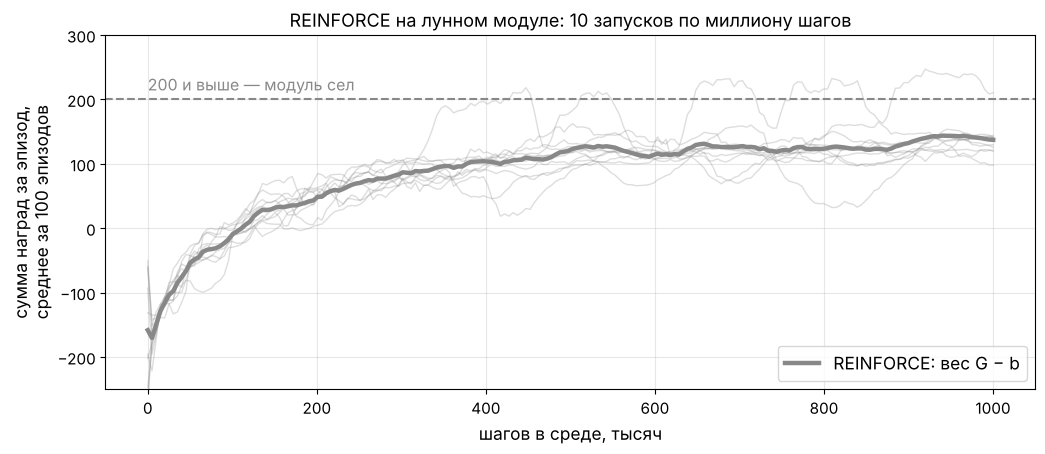

In [5]:
if TRAIN_LANDER:
    reinforce_runs = [train_reinforce(seed)[0] for seed in SEEDS]
else:
    reinforce_runs = load_runs("reinforce")                # сохранённый результат этих же вызовов
print_runs("REINFORCE: вес G − b", reinforce_runs)
plot_lander_steps({"REINFORCE: вес G − b": reinforce_runs}, title="REINFORCE на лунном модуле: 10 запусков по миллиону шагов")
plt.show()

Модуль научился садиться в 1 запуске из 10. В остальных девяти среднее остановилось на 98–144: модуль опускается на поверхность, но не выключает двигатели. Эпизод не заканчивается, +100 за посадку нет, и на 1000-м шаге время выходит — так кончаются от 0 до 95 % последних эпизодов.

Почему так медленно? Посмотрим, какие веса получают действия.

**Вопрос 1.** Модуль у самой поверхности и ещё снижается (кадр ниже). Из этой ситуации мы по 300 раз сыграли каждое из четырёх действий, а дальше — стратегию-сеть до конца эпизода. Средний $G$: ничего не делать — −73, левый двигатель — −53, главный — −24, правый — −79. Число $b$ у этой стратегии равно 7 (средний $G_t$ по шагам ста её эпизодов). Какие веса $G - b$ получат четыре действия?

- **A.** У главного двигателя вес положительный, у остальных отрицательный.
- **B.** У всех четырёх вес отрицательный.
- **C.** У всех четырёх вес положительный.

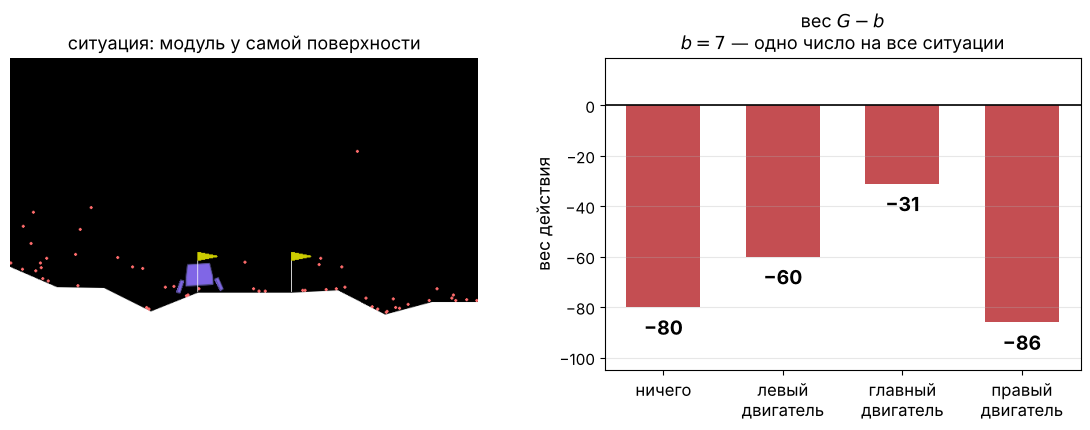

In [6]:
situation = load_situation()
plot_situation(situation, base="b")
plt.show()

Ответ **B** — у всех четырёх действий вес отрицательный: −80, −60, −31 и −86. Даже лучшее действие, главный двигатель, получает $−24 - 7 = −31$: сыграл его агент — оно станет реже. Вес сообщает одно: ситуация плохая. А в удачной ситуации $G$ выше $b$ при любом действии, и чаще становится любое из четырёх.

**Одной строкой:** пока мы сравниваем $G_t$ с одним числом на все ситуации, знак веса говорит о том, в какую ситуацию попал агент, а не о том, какое действие он выбрал.

## 2. Критик: вычитаем то, что от действия не зависит

**Главная идея: вместо одного числа $b$ берём сеть-критик $V_w(s)$ — она предсказывает, какой $G$ обычно получается из состояния $s$, и действие сравнивается с этим прогнозом.**

$G_t$ складывается из двух частей: сколько обычно выходит из состояния $s_t$ — это от выбранного действия не зависит — и насколько сыгранное действие оказалось лучше или хуже обычного. Вычитая первую часть, в весе оставляем только вторую. Поэтому мерка и нужна своя для каждой ситуации: одним числом $b$ первую часть не убрать.

Меняется одно место:

$$\text{REINFORCE:}\quad \text{вес} = G_t - b \qquad\longrightarrow\qquad \text{с критиком:}\quad \text{вес} = G_t - V_w(s_t)$$

$V_w$ — вторая сеть с весами $w$: на входе состояние, на выходе одно число. Разность $G_t - V_w(s_t)$ называют **преимуществом** действия (advantage). В учебниках его пишут как $A(s, a) = Q(s, a) - V(s)$ — насколько действие лучше среднего по этой ситуации; $G_t$ как раз и есть оценка $Q(s_t, a_t)$ по одному сыгранному эпизоду.

> **Простыми словами.** Вопрос к действию теперь не «хорошо ли закончился эпизод?», а «закончился ли он лучше, чем обычно заканчивается из такой ситуации?».

**Вопрос 2.** Та же ситуация и те же четыре действия: $G$ равен −73, −53, −24 и −79. Теперь вычитаем не $b = 7$, а $V(s) = −37$ — средний $G$, который выходит из этой ситуации, когда действия выбирает сама стратегия. Какие действия получат положительный вес?

- **A.** Ни одно — как и раньше.
- **B.** Все четыре.
- **C.** Только те, после которых $G$ выше среднего для этой ситуации.

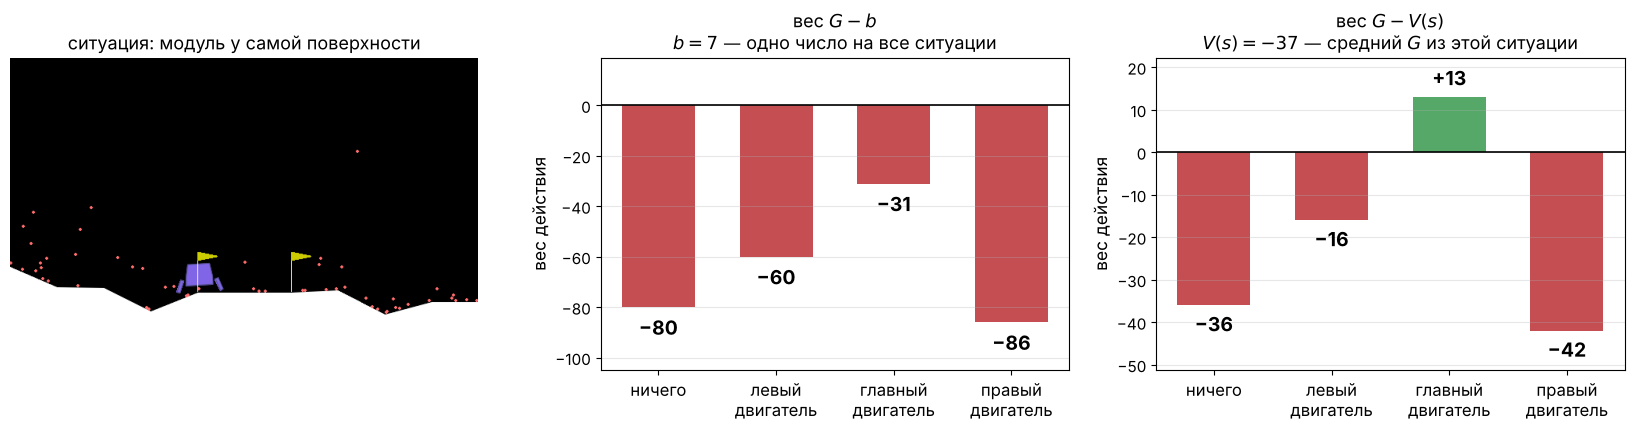

In [7]:
plot_situation(situation, base="both")
plt.show()

Ответ **C** — только те, после которых $G$ выше среднего для этой ситуации. Главный двигатель получает $−24 - (−37) = +13$, остальные три действия — отрицательный вес: −36, −16, −42. Теперь знак веса говорит о действии, а не о ситуации.

Здесь $V(s)$ измерен так же, как четыре числа выше: 300 раз доиграли эту ситуацию стратегией и усреднили $G$. В обучении так не сделать — у каждой ситуации свой $V$, доигрывать каждую по 300 раз слишком дорого. Поэтому $V$ предсказывает сеть.

Критик учится на тех же эпизодах, что и актор: его выход $V_w(s_t)$ подтягиваем к $G_t$ — к тому, что на самом деле получилось после состояния $s_t$. Это регрессия с квадратом ошибки, как у Q-сети на лекции 6:

$$\text{loss} = \underbrace{-\sum_t \big(G_t - V_w(s_t)\big)\log \pi_\theta(a_t \mid s_t)}_{\text{учит актора}} \;+\; \underbrace{\sum_t \big(G_t - V_w(s_t)\big)^2}_{\text{учит критика}}$$

В первом слагаемом (в коде `loss_actor`) разность — просто число, вес действия: градиент через неё в критика не идёт, за это отвечает `.detach()`. Критика учит второе слагаемое, `loss_critic`. На схеме новое место красное, в коде новые строки помечены `# ← новое`.

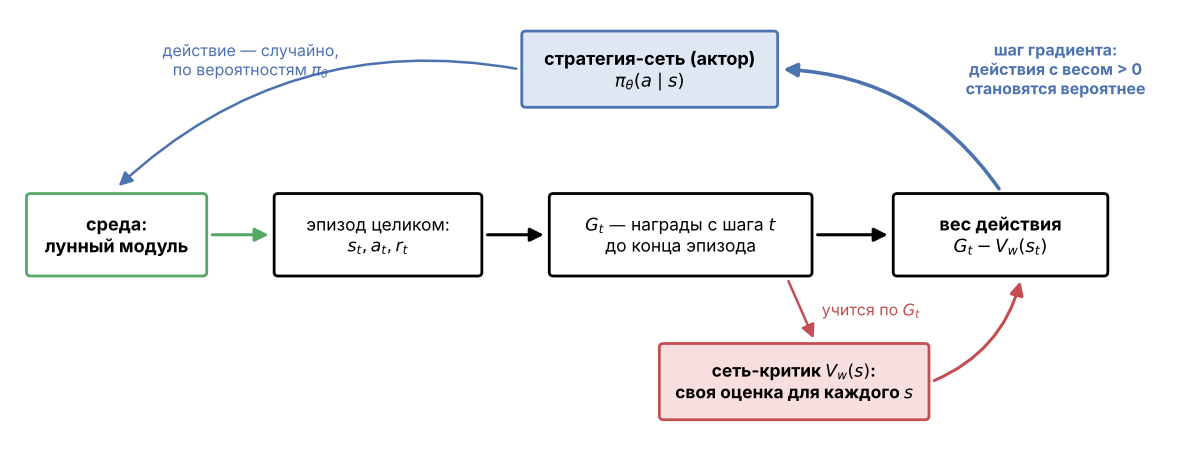

In [8]:
draw_ac_scheme("critic")
plt.show()

In [9]:
def train_critic(seed, steps=STEPS):
    # то же, но вместо числа b — сеть-критик V(s)
    rng, env, actor = np.random.default_rng(seed), make_lander(), make_net(4, seed)
    critic = make_net(1, seed + 1000)                                      # ← новое: сеть-критик, на выходе одно число
    opt = torch.optim.Adam([*actor.parameters(), *critic.parameters()], lr=0.001)
    played, history = 0, []
    while played < steps:
        s, _ = env.reset(seed=seed * 10_000 + len(history))
        states, actions, rewards, *_ = play(actor, env, s, rng, n=1000)
        G = torch.as_tensor(returns_to_go(rewards), dtype=torch.float32)
        V = critic(torch.as_tensor(states)).squeeze(1)                     # ← новое: V(s_t) для каждого шага
        weights = (G - V).detach()                                         # ← новое: вместо G − b; detach — это числа
        loss_actor = -(weights * log_probs_of(actor, states, actions)).sum()
        loss_critic = ((G - V) ** 2).sum()                                 # ← новое: учит критика
        loss = loss_actor + loss_critic
        opt.zero_grad(); loss.backward(); opt.step()
        played += len(rewards); history.append((played, rewards.sum()))
    return np.array(history), actor, critic

с критиком: вес G − V(s)
    среднее последних 100 эпизодов: 208; по запускам: 131 140 154 202 223 234 235 251 251 257; не меньше 200 — в 7 из 10
    к 500 тыс. шагов: 121;  до среднего 200 дошли 7 из 10 запусков, шагов до этого, тыс.: 342 595 683 730 766 870 898
    время вышло (1000 шагов) в последних 100 эпизодах, % по запускам: 0 0 0 0 1 1 3 58 66 71


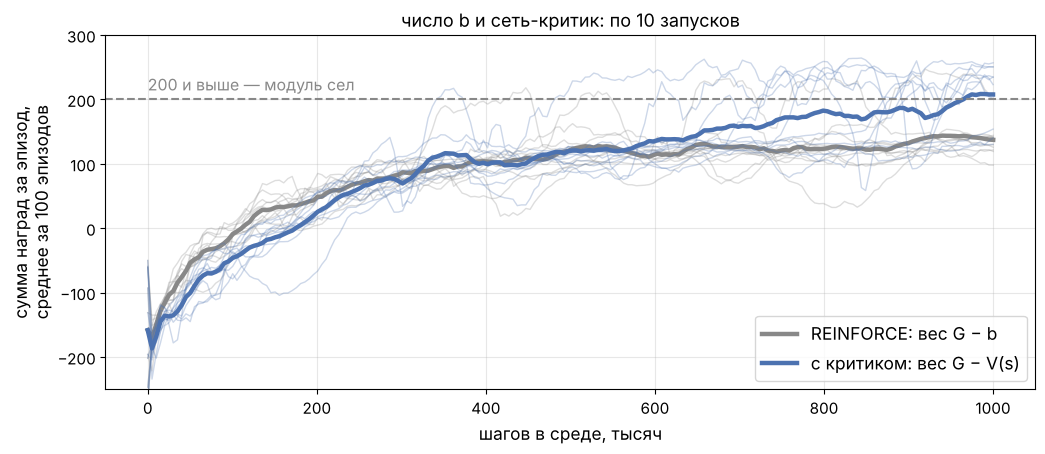

In [10]:
if TRAIN_LANDER:
    critic_runs = [train_critic(seed)[0] for seed in SEEDS]
else:
    critic_runs = load_runs("critic")
print_runs("с критиком: вес G − V(s)", critic_runs)
plot_lander_steps({"REINFORCE: вес G − b": reinforce_runs, "с критиком: вес G − V(s)": critic_runs},
                  title="число b и сеть-критик: по 10 запусков")
plt.show()

С критиком модуль сел в 7 запусках из 10 вместо 1. Среднее за последние 100 эпизодов — 208 против 137. В коде изменились четыре строки.

**Почему так выходит.** С числом $b$ в плохой ситуации отрицательный вес получало любое действие, в хорошей — любое получало положительный; верное направление складывалось только в среднем по многим эпизодам. С критиком знак веса зависит от самого действия. 3 запуска из десяти и с критиком остались на 131–154: модуль там тоже не выключает двигатели.

**Одной строкой:** критик даёт каждой ситуации свою мерку $V(s)$, и вес $G_t - V(s_t)$ оценивает действие, а не ситуацию.

## 3. Не ждём конца эпизода: хвост оценивает критик

**Главная идея: ту часть эпизода, которая ещё не сыграна, заменяет оценка критика — поэтому сети можно обновлять каждые $n$ шагов.**

До сих пор $G_t$ считался по эпизоду целиком, а эпизод у модуля — до 1000 шагов: одно обновление сетей на сотни шагов. Но критик уже умеет предсказывать, сколько наград будет дальше. Сыграем кусок из $n$ шагов и остановимся; состояние после куска обозначим $s_{\text{после}}$:

$$G_t = \underbrace{r_t + \gamma\, r_{t+1} + \dots}_{\text{награды до конца куска}} \;+\; \underbrace{\gamma^{k}\, V_w(s_{\text{после}})}_{\text{хвост: оценка критика}}$$

Здесь $k$ — сколько шагов от шага $t$ до конца куска. Это та же замена, что в цели Q-сети $y = r + \gamma \max_{a'} Q(s', a')$: настоящие награды плюс оценка всего остального. Если внутри куска модуль сел или разбился, хвоста нет.

Если взять кусок из одного шага, вес действия окажется равен $r_t + \gamma V_w(s_{t+1}) - V_w(s_t)$ — это TD-ошибка из лекции 6. Классический актор-критик записывают именно так: актор шагает по TD-ошибке, критик её же уменьшает.

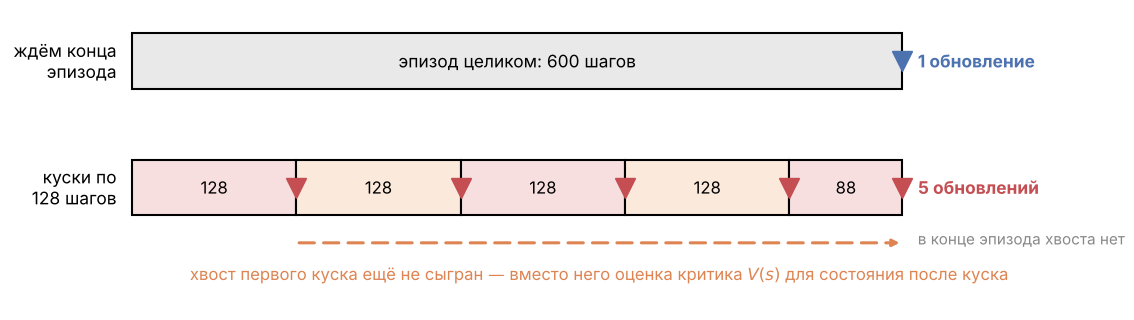

In [11]:
draw_pieces(length=600, n=128)
plt.show()

**Вопрос 3.** Сети обновляются после каждых 128 шагов, а не после эпизода. Хвост — оценка критика, а критик сам ещё учится. Как пойдёт обучение по сравнению с разделом 2?

- **A.** Модуль сядет раньше, и дальше результат будет держаться.
- **B.** Модуль сядет раньше, но результат будет держаться хуже.
- **C.** Модуль не сядет: критик ошибается, и его ошибка портит веса действий.

В коде три новые строки: кусок вместо эпизода, хвост, $G_t$ с хвостом. `terminated` значит, что модуль сел или разбился, — тогда хвост равен нулю; `truncated` — что вышло время эпизода. И одна настройка: у критика шаг обучения больше, чем у актора, — его оценка теперь входит в $G_t$.

In [12]:
def train_ac(seed, steps=STEPS, n=128):
    # актор-критик: сети обновляются после каждого куска из n шагов, хвост эпизода оценивает критик
    rng, env, actor, critic = np.random.default_rng(seed), make_lander(), make_net(4, seed), make_net(1, seed + 1000)
    opt = torch.optim.Adam([{"params": actor.parameters(), "lr": 0.0007},
                            {"params": critic.parameters(), "lr": 0.003}])               # ← новое: у критика шаг больше
    played, total, history = 0, 0.0, []
    s, _ = env.reset(seed=seed * 10_000)
    while played < steps:
        states, actions, rewards, s, terminated, truncated = play(actor, env, s, rng, n)  # ← новое: кусок из n шагов
        tail = 0.0 if terminated else critic(torch.as_tensor(s)).item()                   # ← новое: хвост — оценка критика
        G = torch.as_tensor(returns_to_go(rewards, tail=tail), dtype=torch.float32)       # ← новое: G_t с хвостом
        V = critic(torch.as_tensor(states)).squeeze(1)
        weights = (G - V).detach()
        loss_actor = -(weights * log_probs_of(actor, states, actions)).sum()
        loss_critic = ((G - V) ** 2).sum()
        loss = loss_actor + loss_critic
        opt.zero_grad(); loss.backward(); opt.step()
        played += len(rewards); total += rewards.sum()
        if terminated or truncated:                                                       # эпизод закончился — начинаем новый
            history.append((played, total)); total = 0.0
            s, _ = env.reset(seed=seed * 10_000 + len(history))
    return np.array(history), actor, critic

актор-критик: куски по 128 шагов
    среднее последних 100 эпизодов: 155; по запускам: 61 122 130 143 154 154 174 183 213 215; не меньше 200 — в 2 из 10
    к 500 тыс. шагов: 158;  до среднего 200 дошли 6 из 10 запусков, шагов до этого, тыс.: 386 425 440 485 504 527
    время вышло (1000 шагов) в последних 100 эпизодах, % по запускам: 0 1 1 1 2 3 6 48 75 83


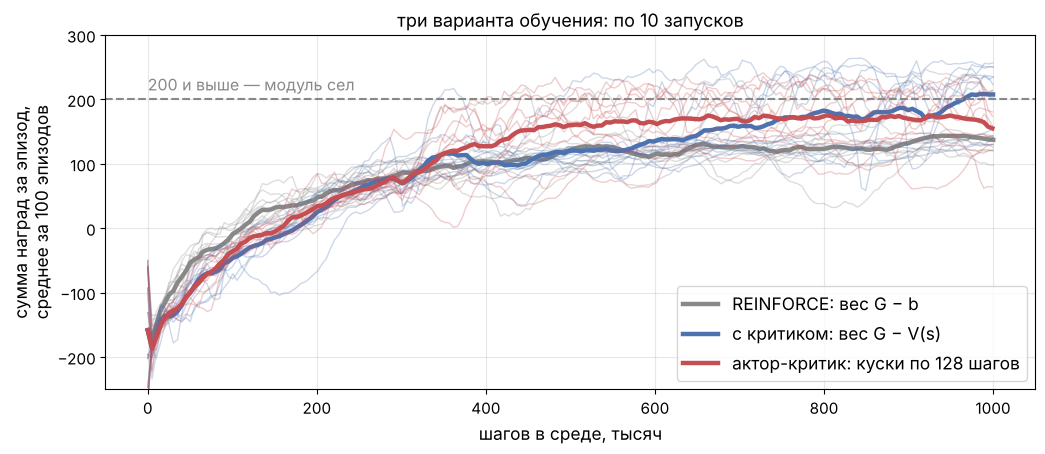

In [13]:
if TRAIN_LANDER:
    ac_runs = [train_ac(seed)[0] for seed in SEEDS]
else:
    ac_runs = load_runs("ac")
print_runs("актор-критик: куски по 128 шагов", ac_runs)
plot_lander_steps({"REINFORCE: вес G − b": reinforce_runs, "с критиком: вес G − V(s)": critic_runs,
                   "актор-критик: куски по 128 шагов": ac_runs}, title="три варианта обучения: по 10 запусков")
plt.show()

Ответ **B** — модуль садится раньше, но результат держится хуже. До среднего 200 дошли 6 запусков из 10, всем хватило 386–527 тысяч шагов; с критиком по эпизодам — 7 запусков, но шести из них понадобилось 595–898 тысяч. А после миллиона шагов среднее 200 держат только 2 запуска из 10 против 7.

**Почему так выходит.** Быстрее: сети обновляются чаще (на картинке 5 раз вместо 1). Хуже держит: оценка критика входит в веса всех действий куска, а критик учится по своим же оценкам, как Q-сеть на лекции 7. Ошибся критик — неверны веса действий.

Этот вариант и называют **актор-критик** (A2C). Он работает и там, где эпизод очень длинный или не кончается вовсе. Как удержать результат — тема следующей лекции, PPO.

**Одной строкой:** актор-критик не ждёт конца эпизода — хвост заменяет оценка критика; учится он быстрее, но держит результат хуже.

## 4. Актор-критик и DQN на одном модуле

**Главная идея: DQN тратит меньше шагов в среде, потому что учится на каждом переходе много раз; актор-критик использует переход один раз, зато работает и там, где действие — число, а не одна из нескольких кнопок.**

Две стратегии-сети из этой лекции на одном и том же старте. Слева REINFORCE: модуль опустился на площадку, но двигатели не выключил — эпизод шёл все 1000 шагов, сумма наград 146. Справа актор-критик: модуль сел за 238 шагов, сумма наград 267. Показаны первые 280 шагов. У обоих запуск 0; для актора-критика это один из двух запусков, удержавших посадку.

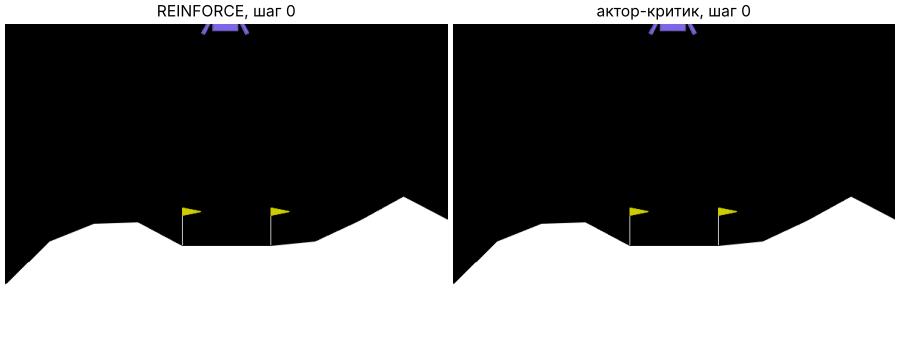

**Вопрос 4.** DQN на лекции 7 дошёл до среднего 200 за 114–241 тысяч шагов в среде — во всех 3 запусках (ячейка ниже считает это по тем же запускам). Актору-критику понадобилось 386–527 тысяч шагов, и дошли 6 запусков из 10. Почему DQN хватает меньше шагов?

- **A.** У DQN сеть больше.
- **B.** DQN хранит переходы в буфере и учится на каждом много раз, актор-критик использует переход один раз.
- **C.** DQN не делает случайных действий.

In [9]:
# три запуска DQN лекции 7, посчитанные тем же train_lander со счётчиком шагов в среде
for name, histories in (("DQN (лекция 7)", load_runs("dqn")), ("актор-критик", ac_runs)):
    reached = [round(steps_to_land(history) / 1000) for history in histories if steps_to_land(history)]
    print(f"{name:15s} до среднего 200 дошли {len(reached)} из {len(histories)} запусков,"
          f" шагов в среде, тыс.: {' '.join(map(str, sorted(reached)))}")

DQN (лекция 7)  до среднего 200 дошли 3 из 3 запусков, шагов в среде, тыс.: 114 214 241
актор-критик    до среднего 200 дошли 6 из 10 запусков, шагов в среде, тыс.: 386 425 440 485 504 527


Ответ **B** — DQN хранит переходы в буфере и учится на каждом много раз: на каждый шаг в среде он берёт пачку из 64 переходов, так что один переход участвует в обучении в среднем около 64 раз. Актор-критик сыграл кусок, сделал один шаг градиента и больше к этому куску не возвращается.

Сложить куски в буфер нельзя: градиент стратегии — среднее по эпизодам **текущей** стратегии (лекция 5), а в буфере лежали бы шаги прежних стратегий. Такие методы называют on-policy (лекция 4).

| | DQN (лекция 7) | актор-критик |
|---|---|---|
| что выдаёт сеть | оценку $Q(s, a)$ каждого действия | вероятности действий и оценку $V(s)$ |
| на чём учится | на переходах из буфера, каждый — много раз | на свежем куске, каждый переход — один раз |
| шагов в среде до среднего 200 | 114–241 тысяч, 3 запуска из 3 | 386–527 тысяч, 6 запусков из 10 |
| какие действия умеет | только несколько кнопок: нужен $\max$ по действиям | и кнопки, и числа: перебор не нужен |

Последняя строка — не про наш модуль: у него четыре кнопки, и $\max$ по ним берётся легко. Но у того же модуля есть вариант, где действие — **два числа** от −1 до 1: насколько открыт главный двигатель и насколько боковой. У робота это углы всех суставов. Перебрать такие действия нельзя: их бесконечно много, и $\max_a Q(s, a)$ не взять — DQN там неприменим. Стратегия-сеть ничего не перебирает: вместо вероятностей четырёх кнопок она выдаёт **среднее и разброс**, а действие берётся случайно из этого распределения.

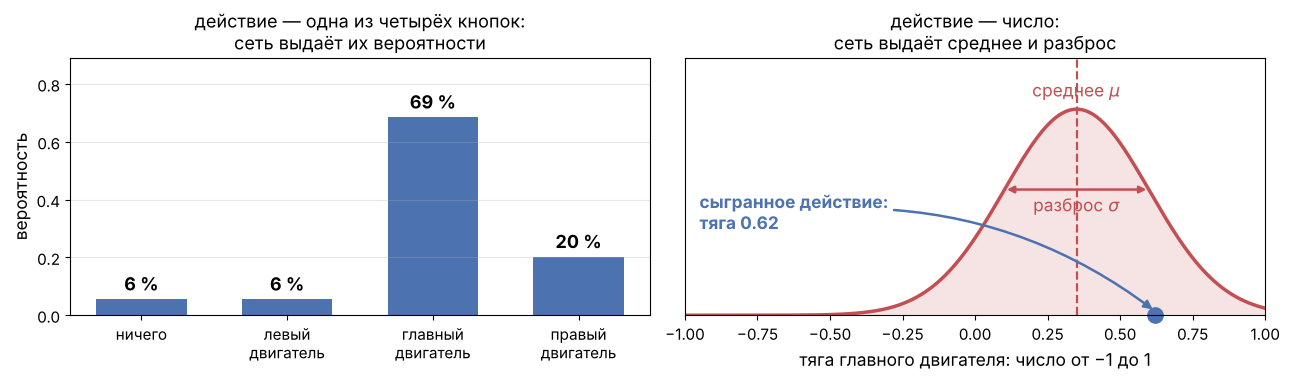

In [4]:
draw_action_kinds(situation["probs"])     # слева — вероятности из ситуации раздела 2
plt.show()

Формула веса и строка loss при этом не меняются: $G_t - V_w(s_t)$ остаётся тем же числом. Меняется только, как считается $\log \pi_\theta(a_t \mid s_t)$ — вместо логарифма вероятности кнопки берётся логарифм плотности нормального распределения в сыгранной точке.

**Одной строкой:** DQN бережёт шаги в среде, актор-критик работает и с непрерывными действиями — на этом построены PPO и управление роботами.

## 5. Итоги

1. **REINFORCE** сравнивает $G_t$ с одним числом $b$. В плохой ситуации отрицательный вес получает любое действие, в хорошей — любое получает положительный. За миллион шагов модуль сел в 1 запуске из 10.
2. **Критик** $V_w(s)$ — сеть, которая предсказывает $G$ из состояния $s$. Вес действия $G_t - V_w(s_t)$ — преимущество: насколько вышло лучше, чем обычно из этой ситуации. Модуль сел в 7 запусках из 10.
3. **Хвост эпизода** заменяет оценка критика: $G_t$ = награды куска + $\gamma^k V_w(s_{\text{после}})$. Сети обновляются каждые $n$ шагов. Модуль выходит на посадку раньше (386–527 тысяч шагов; с критиком по эпизодам — чаще 595–898), но держит результат хуже: после миллиона шагов — 2 запуска из 10.
4. **Актор-критик в четырёх шагах:** сыграть кусок из $n$ шагов → посчитать $G_t$ с хвостом → вес действия $G_t - V_w(s_t)$ → один шаг градиента для обеих сетей.
5. **Плата за on-policy:** переход используется один раз. DQN с буфером хватило 114–241 тысяч шагов. Зато актору-критику не нужен $\max$ по действиям — он работает и там, где действие — число: например, насколько открыть двигатель.

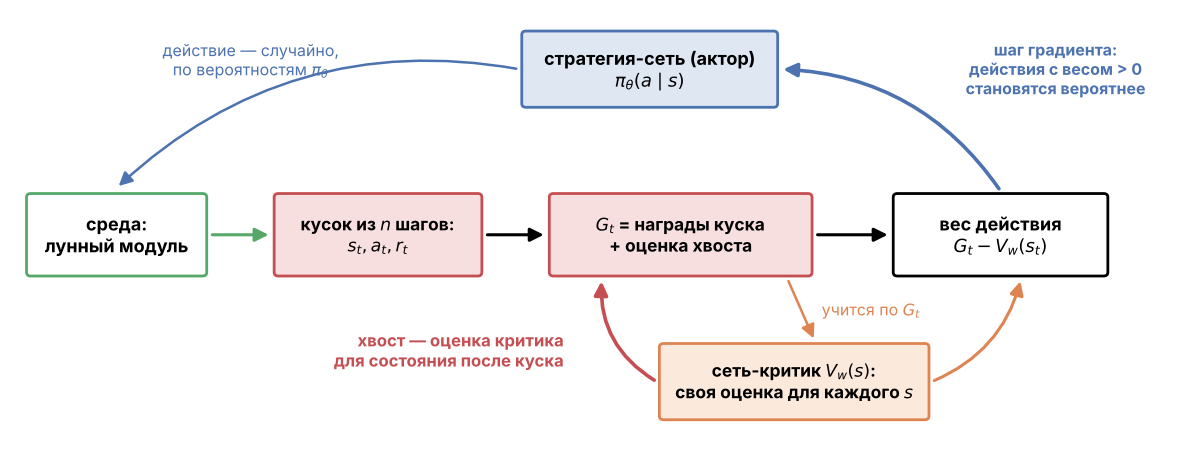

In [14]:
draw_ac_scheme("tail")
plt.show()

> **Простыми словами — вся лекция.** Актор играет, критик говорит, вышло лучше или хуже, чем он ожидал. Что вышло лучше ожиданий — актор делает чаще. А сам критик поправляет ожидания по тому, что получилось.

**Что дальше.** Актор-критик быстро выходит на посадку, но плохо держит результат. На следующей лекции — PPO: он ограничивает, насколько один шаг градиента может изменить стратегию, и использует каждый кусок несколько раз.

Словарь лекции: **актор (actor), критик (critic), преимущество (advantage), актор-критик (actor-critic, A2C)**.

## Литература

* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 13: REINFORCE с вычитанием оценки состояния — раздел 13.4, актор-критик — раздел 13.5. [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* Mnih V. и др. *Asynchronous methods for deep reinforcement learning*. ICML, 2016 — A3C и A2C: актор-критик с кусками по $n$ шагов в нескольких копиях среды.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* **Домашка блока 3** (лекция 5: градиент стратегии и REINFORCE) — дедлайн 22 ноября, 23:59 МСК.